In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train_df = pd.read_csv(r'/Users/pawn/Desktop/NTI/Customer Segmentation Classification/Train.csv')
test_df = pd.read_csv(r'/Users/pawn/Desktop/NTI/Customer Segmentation Classification/Test.csv')

df = train_df.copy()

print('Training data shape:', train_df.shape)
print('Testing data shape:', test_df.shape)
df

Training data shape: (8068, 11)
Testing data shape: (2627, 11)


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A
...,...,...,...,...,...,...,...,...,...,...,...
8063,464018,Male,No,22,No,NaN,0.0,Low,7.0,Cat_1,D
8064,464685,Male,No,35,No,Executive,3.0,Low,4.0,Cat_4,D
8065,465406,Female,No,33,Yes,Healthcare,1.0,Low,1.0,Cat_6,D
8066,467299,Female,No,27,Yes,Healthcare,1.0,Low,4.0,Cat_6,B


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8068 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               8068 non-null   int64  
 1   Gender           8068 non-null   object 
 2   Ever_Married     7928 non-null   object 
 3   Age              8068 non-null   int64  
 4   Graduated        7990 non-null   object 
 5   Profession       7944 non-null   object 
 6   Work_Experience  7239 non-null   float64
 7   Spending_Score   8068 non-null   object 
 8   Family_Size      7733 non-null   float64
 9   Var_1            7992 non-null   object 
 10  Segmentation     8068 non-null   object 
dtypes: float64(2), int64(2), object(7)
memory usage: 693.5+ KB


In [4]:
df.describe()

,ID,Age,Work_Experience,Family_Size
count,8068.000000,8068.000000,7239.000000,7733.000000
mean,463479.214551,43.466906,2.641663,2.850123
std,2595.381232,16.711696,3.406763,1.531413
min,458982.000000,18.000000,0.000000,1.000000
25%,461240.750000,30.000000,0.000000,2.000000
50%,463472.500000,40.000000,1.000000,3.000000
75%,465744.250000,53.000000,4.000000,4.000000
max,467974.000000,89.000000,14.000000,9.000000


In [5]:
df.duplicated().sum()

0

In [6]:
print('Training duplicate rows:', train_df.duplicated().sum())
print('Testing duplicate rows:', test_df.duplicated().sum())

train_df.drop_duplicates(inplace=True)
test_df.drop_duplicates(inplace=True)

train_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)
df = train_df.copy()

Training duplicate rows: 0
Testing duplicate rows: 0


In [7]:
df.shape

(8068, 11)

In [8]:
df.drop(['ID'], axis=1, inplace=True)
test_df.drop(['ID'], axis=1, inplace=True)

In [9]:
df

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A
...,...,...,...,...,...,...,...,...,...,...
8063,Male,No,22,No,NaN,0.0,Low,7.0,Cat_1,D
8064,Male,No,35,No,Executive,3.0,Low,4.0,Cat_4,D
8065,Female,No,33,Yes,Healthcare,1.0,Low,1.0,Cat_6,D
8066,Female,No,27,Yes,Healthcare,1.0,Low,4.0,Cat_6,B


In [10]:
df.isnull().sum().sort_values(ascending = False)

Work_Experience    829
Family_Size        335
Ever_Married       140
Profession         124
Graduated           78
Var_1               76
Gender               0
Age                  0
Spending_Score       0
Segmentation         0
dtype: int64

array([[<Axes: title={'center': 'Work_Experience'}>]], dtype=object)

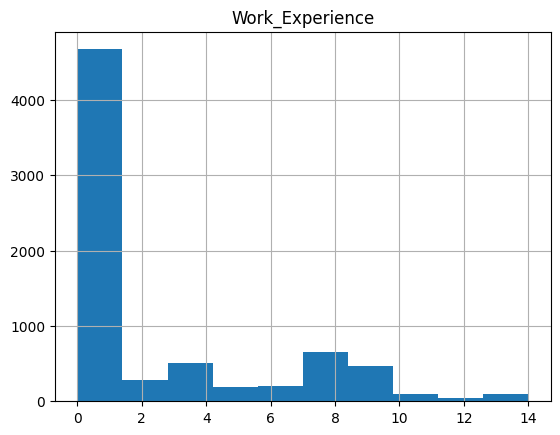

In [11]:
df.hist(['Work_Experience'])

In [12]:
df['Work_Experience'].skew()

1.3062257604935081

In [13]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='median')
imputer.fit(df[['Work_Experience']])
df[['Work_Experience']] = imputer.transform(df[['Work_Experience']])
test_df[['Work_Experience']] = imputer.transform(test_df[['Work_Experience']])

In [14]:
df['Work_Experience'].isnull().sum()

0

In [15]:
df.isnull().sum().sort_values(ascending = False)

Family_Size        335
Ever_Married       140
Profession         124
Graduated           78
Var_1               76
Gender               0
Age                  0
Work_Experience      0
Spending_Score       0
Segmentation         0
dtype: int64

array([[<Axes: title={'center': 'Family_Size'}>]], dtype=object)

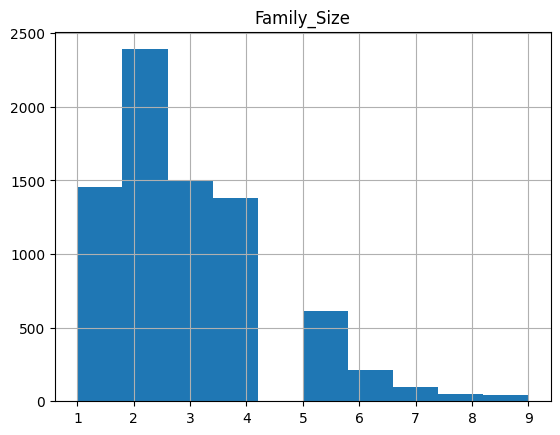

In [16]:
df.hist(['Family_Size'])

In [17]:
df['Family_Size'].skew()

1.010804210772843

In [18]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='median')
imputer.fit(df[['Family_Size']])
df[['Family_Size']] = imputer.transform(df[['Family_Size']])
test_df[['Family_Size']] = imputer.transform(test_df[['Family_Size']])

<Axes: >

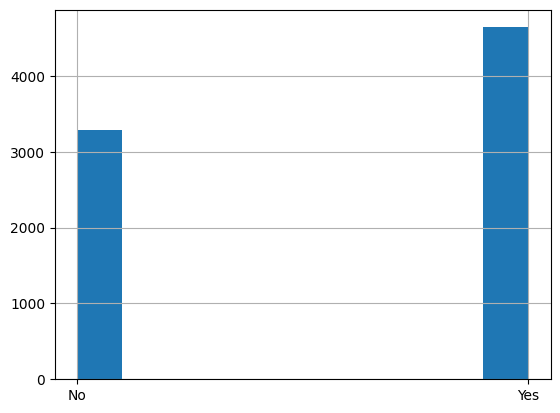

In [19]:
df['Ever_Married'].hist()

In [20]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
imputer.fit(df[['Ever_Married']])
df[['Ever_Married']] = imputer.transform(df[['Ever_Married']])
test_df[['Ever_Married']] = imputer.transform(test_df[['Ever_Married']])

In [21]:
df.columns

Index(['Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession',
       'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1',
       'Segmentation'],
      dtype='object')

In [22]:
df.isnull().sum().sort_values()

Gender               0
Ever_Married         0
Age                  0
Work_Experience      0
Spending_Score       0
Family_Size          0
Segmentation         0
Var_1               76
Graduated           78
Profession         124
dtype: int64

In [23]:
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

for col in ['Var_1', 'Graduated', 'Profession']:
    imputer.fit(df[[col]])
    df[[col]] = imputer.transform(df[[col]])
    test_df[[col]] = imputer.transform(test_df[[col]])

In [24]:
df.isnull().sum().sort_values()

Gender             0
Ever_Married       0
Age                0
Graduated          0
Profession         0
Work_Experience    0
Spending_Score     0
Family_Size        0
Var_1              0
Segmentation       0
dtype: int64

In [25]:
df.select_dtypes(include=['object']).columns

Index(['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score',
       'Var_1', 'Segmentation'],
      dtype='object')

In [26]:
for col in df.select_dtypes(include=['object']).columns:
    print(f'number of column {col} is : ',df[col].nunique())
    print(f'number of column {col} is : ',df[col].unique())

number of column Gender is :  2
number of column Gender is :  ['Male' 'Female']
number of column Ever_Married is :  2
number of column Ever_Married is :  ['No' 'Yes']
number of column Graduated is :  2
number of column Graduated is :  ['No' 'Yes']
number of column Profession is :  9
number of column Profession is :  ['Healthcare' 'Engineer' 'Lawyer' 'Entertainment' 'Artist' 'Executive'
 'Doctor' 'Homemaker' 'Marketing']
number of column Spending_Score is :  3
number of column Spending_Score is :  ['Low' 'Average' 'High']
number of column Var_1 is :  7
number of column Var_1 is :  ['Cat_4' 'Cat_6' 'Cat_7' 'Cat_3' 'Cat_1' 'Cat_2' 'Cat_5']
number of column Segmentation is :  4
number of column Segmentation is :  ['D' 'A' 'B' 'C']


In [27]:
from sklearn.preprocessing import LabelBinarizer

for col in ['Gender', 'Graduated', 'Ever_Married']:
    label_encoder = LabelBinarizer()
    df[col] = label_encoder.fit_transform(df[col]).ravel()
    test_df[col] = label_encoder.transform(test_df[col]).ravel()

In [28]:
from sklearn.preprocessing import OrdinalEncoder

spending_encoder = OrdinalEncoder(categories=[['Low', 'Average', 'High']])
df['Spending_Score'] = spending_encoder.fit_transform(
    df[['Spending_Score']]
).ravel()
test_df['Spending_Score'] = spending_encoder.transform(
    test_df[['Spending_Score']]
).ravel()

In [29]:
for col in df.select_dtypes(include=['object']).columns:
    print(f'number of column {col} is : ',df[col].nunique())
    print(f'number of column {col} is : ',df[col].unique())

number of column Profession is :  9
number of column Profession is :  ['Healthcare' 'Engineer' 'Lawyer' 'Entertainment' 'Artist' 'Executive'
 'Doctor' 'Homemaker' 'Marketing']
number of column Var_1 is :  7
number of column Var_1 is :  ['Cat_4' 'Cat_6' 'Cat_7' 'Cat_3' 'Cat_1' 'Cat_2' 'Cat_5']
number of column Segmentation is :  4
number of column Segmentation is :  ['D' 'A' 'B' 'C']


In [30]:
import  category_encoders as ce

In [31]:
target_enc = ce.TargetEncoder(
    cols=['Profession'],
    smoothing=5
)

## Frequency Encoding (Count Encoding)



In [32]:
freq = df['Profession'].value_counts()
profession_frequency = df['Profession'].map(freq)
profession_frequency.head()

0    1332
1     699
2     699
3     623
4     949
Name: Profession, dtype: int64

## Binary Encoding



In [33]:
binary_encoder = ce.BinaryEncoder(cols=['Profession'])
profession_binary = binary_encoder.fit_transform(df[['Profession']])
profession_binary.head()

,Profession_0,Profession_1,Profession_2,Profession_3
0,0,0,0,1
1,0,0,1,0
2,0,0,1,0
3,0,0,1,1
4,0,1,0,0


### Leave-One-Out and CatBoost Encoding


## OneHotEncoder


In [34]:
from sklearn.preprocessing import OneHotEncoder

nominal_columns = ['Profession', 'Var_1']
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
train_encoded = ohe.fit_transform(df[nominal_columns])
test_encoded = ohe.transform(test_df[nominal_columns])
encoded_columns = ohe.get_feature_names_out(nominal_columns)

train_ohe_df = pd.DataFrame(
    train_encoded,
    columns=encoded_columns,
    index=df.index
)
test_ohe_df = pd.DataFrame(
    test_encoded,
    columns=encoded_columns,
    index=test_df.index
)

df = pd.concat([df.drop(columns=nominal_columns), train_ohe_df], axis=1)
test_df = pd.concat([test_df.drop(columns=nominal_columns), test_ohe_df], axis=1)

print('Training encoded shape:', df.shape)
print('Testing encoded shape:', test_df.shape)
df.head()

Training encoded shape: (8068, 24)
Testing encoded shape: (2627, 24)


,Gender,Ever_Married,Age,Graduated,Work_Experience,Spending_Score,Family_Size,Segmentation,Profession_Artist,Profession_Doctor,...,Profession_Homemaker,Profession_Lawyer,Profession_Marketing,Var_1_Cat_1,Var_1_Cat_2,Var_1_Cat_3,Var_1_Cat_4,Var_1_Cat_5,Var_1_Cat_6,Var_1_Cat_7
0,1,0,22,0,1.0,0.0,4.0,D,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0,1,38,1,1.0,1.0,3.0,A,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0,1,67,1,1.0,0.0,1.0,B,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1,1,67,1,0.0,2.0,2.0,B,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0,1,40,1,1.0,2.0,6.0,A,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


# Outliers


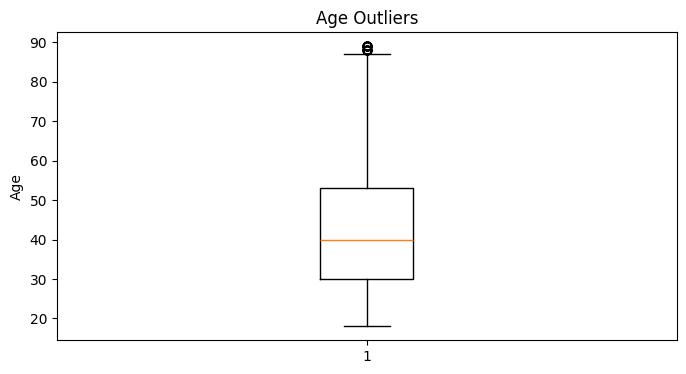

In [35]:
plt.figure(figsize=(8, 4))
plt.boxplot(df['Age'])
plt.title('Age Outliers')
plt.ylabel('Age')
plt.show()

## Methods to Detect Outliers (IQR)

In [36]:
def remove_outliers_iqr(data, column_name='Age'):
    q1 = data[column_name].quantile(0.25)
    q3 = data[column_name].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return data[(data[column_name] >= lower) & (data[column_name] <= upper)]

cleaned_df_iqr = remove_outliers_iqr(df, column_name='Age')
print('Original shape:', df.shape, '| After IQR filter:', cleaned_df_iqr.shape)

Original shape: (8068, 24) | After IQR filter: (7997, 24)


## Methods to Detect Outliers (Z-score)



In [37]:
def remove_outliers_zscore(data, column_name='Age', threshold=3.0):
    values = data[column_name]
    z_scores = (values - values.mean()) / values.std(ddof=0)
    return data[z_scores.abs() < threshold]

cleaned_df_zscore = remove_outliers_zscore(df, column_name='Age', threshold=3.0)
print('Original shape:', df.shape, '| After Z-score filter:', cleaned_df_zscore.shape)

Original shape: (8068, 24) | After Z-score filter: (8068, 24)


## Methods to Detect Outliers (Isolation Forest)

In [38]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.05, random_state=42)
isolation_flags = iso.fit_predict(df[['Age']])
df_clean_iso = df.loc[isolation_flags == 1].copy()
print('Rows flagged:', (isolation_flags == -1).sum())
print('Rows retained:', df_clean_iso.shape[0])

Rows flagged: 385
Rows retained: 7683


## Methods to Detect Outliers (Local Outlier Factor)

In [39]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(contamination=0.05)
lof_flags = lof.fit_predict(df[['Age']])
df_clean_lof = df.loc[lof_flags == 1].copy()
print('Rows flagged:', (lof_flags == -1).sum())
print('Rows retained:', df_clean_lof.shape[0])

Rows flagged: 0
Rows retained: 8068


## Methods to Detect Outliers (Elliptic Envelope)

In [40]:
from sklearn.covariance import EllipticEnvelope

ell = EllipticEnvelope(contamination=0.05, random_state=42)
ell_flags = ell.fit_predict(df[['Age']])
df_clean_ell = df.loc[ell_flags == 1].copy()
print('Rows flagged:', (ell_flags == -1).sum())
print('Rows retained:', df_clean_ell.shape[0])

Rows flagged: 384
Rows retained: 7684


In [41]:
def estimate_contamination(data, column_name):
    q1 = data[column_name].quantile(0.25)
    q3 = data[column_name].quantile(0.75)
    iqr = q3 - q1
    outliers = (data[column_name] < q1 - 1.5 * iqr) | (data[column_name] > q3 + 1.5 * iqr)
    return outliers.mean()

estimate_contamination(df, 'Age')

0.00880019831432821

### Remove Outliers (drop them)

In [42]:
cleaned_df = remove_outliers_iqr(df, 'Age')
print(df.shape, cleaned_df.shape)

(8068, 24) (7997, 24)


### Cap (Winsorize)

In [43]:
from scipy.stats.mstats import winsorize

age_winsorized = winsorize(df['Age'], limits=(0.05, 0.05))
print('Original range:', df['Age'].min(), df['Age'].max())
print('Winsorized range:', age_winsorized.min(), age_winsorized.max())

Original range: 18 89
Winsorized range: 21 77


### Clip (Set min/max thresholds)

In [44]:
q1 = df['Age'].quantile(0.25)
q3 = df['Age'].quantile(0.75)
iqr = q3 - q1
age_clipped = df['Age'].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

print('Original range:', df['Age'].min(), df['Age'].max())
print('Clipped range:', age_clipped.min(), age_clipped.max())

Original range: 18 89
Clipped range: 18.0 87.5


# Splitting Data
### Train/Test Split

In [45]:
X_train = df.drop(['Segmentation'], axis=1)
y_train = df['Segmentation']

X_test = test_df.drop(['Segmentation'], axis=1)
y_test = test_df['Segmentation']
X_test = X_test.reindex(columns=X_train.columns)

print('Feature columns match:', X_train.columns.equals(X_test.columns))
print('X_train =', X_train.shape, 'y_train =', y_train.shape)
print('X_test  =', X_test.shape, 'y_test  =', y_test.shape)

Feature columns match: True
X_train = (8068, 23) y_train = (8068,)
X_test  = (2627, 23) y_test  = (2627,)


# Data Transformation

## Log1p

In [46]:
def log_transform(data):
    return np.log(data + 1)

X_train['Work_Experience'] = log_transform(X_train['Work_Experience'])
X_test['Work_Experience'] = log_transform(X_test['Work_Experience'])

## Box-Cox

Use Box-Cox only with strictly positive values. `Age` satisfies this condition.

In [47]:
from sklearn.preprocessing import PowerTransformer

pt_boxcox = PowerTransformer(method='box-cox')
X_train[['Age']] = pt_boxcox.fit_transform(X_train[['Age']])
X_test[['Age']] = pt_boxcox.transform(X_test[['Age']])

## Yeo-Johnson

Yeo-Johnson supports zero and positive or negative values.

In [48]:
pt_yeojohnson = PowerTransformer(method='yeo-johnson')
X_train[['Family_Size']] = pt_yeojohnson.fit_transform(X_train[['Family_Size']])
X_test[['Family_Size']] = pt_yeojohnson.transform(X_test[['Family_Size']])

# Data Scaling (Normalization)

## MinMaxScaler

In [49]:
from sklearn.preprocessing import MinMaxScaler

my_scaler = MinMaxScaler(feature_range=(0, 1))
X_train[['Age']] = my_scaler.fit_transform(X_train[['Age']])
X_test[['Age']] = my_scaler.transform(X_test[['Age']])

## StandardScaler

In [50]:
from sklearn.preprocessing import StandardScaler

my_scaler = StandardScaler()
X_train[['Work_Experience']] = my_scaler.fit_transform(X_train[['Work_Experience']])
X_test[['Work_Experience']] = my_scaler.transform(X_test[['Work_Experience']])

## RobustScaler

In [51]:
from sklearn.preprocessing import RobustScaler

my_scaler = RobustScaler()
X_train[['Family_Size']] = my_scaler.fit_transform(X_train[['Family_Size']])
X_test[['Family_Size']] = my_scaler.transform(X_test[['Family_Size']])

In [52]:
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (8068, 23)
X_test: (2627, 23)
y_train: (8068,)
y_test: (2627,)


In [53]:
df

,Gender,Ever_Married,Age,Graduated,Work_Experience,Spending_Score,Family_Size,Segmentation,Profession_Artist,Profession_Doctor,...,Profession_Homemaker,Profession_Lawyer,Profession_Marketing,Var_1_Cat_1,Var_1_Cat_2,Var_1_Cat_3,Var_1_Cat_4,Var_1_Cat_5,Var_1_Cat_6,Var_1_Cat_7
0,1,0,22,0,1.0,0.0,4.0,D,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0,1,38,1,1.0,1.0,3.0,A,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0,1,67,1,1.0,0.0,1.0,B,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1,1,67,1,0.0,2.0,2.0,B,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0,1,40,1,1.0,2.0,6.0,A,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8063,1,0,22,0,0.0,0.0,7.0,D,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8064,1,0,35,0,3.0,0.0,4.0,D,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
8065,0,0,33,1,1.0,0.0,1.0,D,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8066,0,0,27,1,1.0,0.0,4.0,B,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [54]:
from sklearn.linear_model import LogisticRegression

In [55]:
model = LogisticRegression(
    
    C = 1.0,
    # solver='lbfgs',
    max_iter=200,
    fit_intercept=True,
)


In [56]:
model.fit(X_train , y_train)

LogisticRegression(max_iter=200)

In [57]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score , classification_report

In [58]:
y_pred = model.predict(X_test)

In [59]:
score = accuracy_score(y_test , y_pred)
print(score)

0.32736962314427104


## Additional visualizations (customer segmentation)

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme(style='whitegrid')
cs = pd.read_csv(r'/Users/pawn/Desktop/NTI/Customer Segmentation Classification/Train.csv')
cs.shape

(8068, 11)

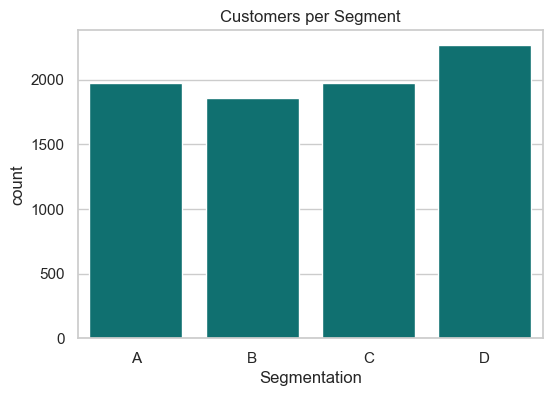

In [61]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Segmentation', data=cs, order=sorted(cs['Segmentation'].unique()), color='teal')
plt.title('Customers per Segment')
plt.show()

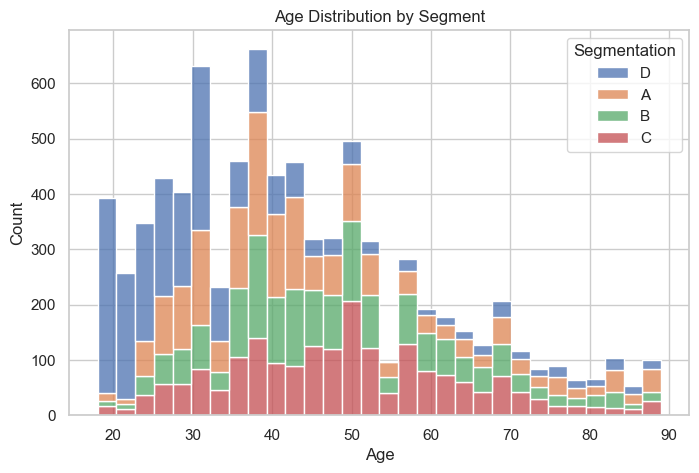

In [62]:
plt.figure(figsize=(8, 5))
sns.histplot(data=cs, x='Age', hue='Segmentation', bins=30, multiple='stack')
plt.title('Age Distribution by Segment')
plt.show()

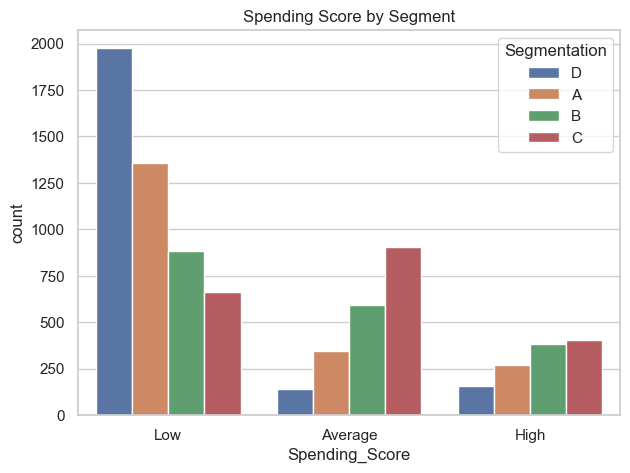

In [63]:
plt.figure(figsize=(7, 5))
sns.countplot(x='Spending_Score', data=cs, hue='Segmentation', order=['Low', 'Average', 'High'])
plt.title('Spending Score by Segment')
plt.show()

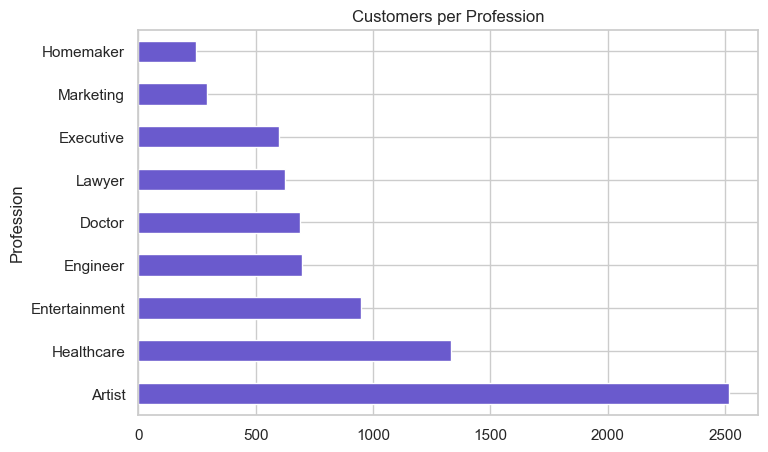

In [64]:
plt.figure(figsize=(8, 5))
cs['Profession'].value_counts().plot(kind='barh', color='slateblue')
plt.title('Customers per Profession')
plt.show()

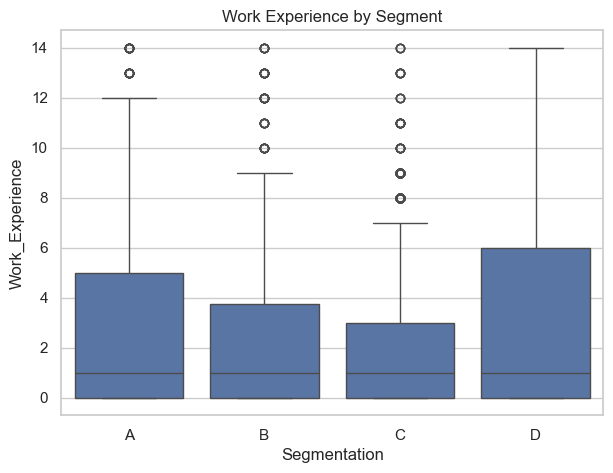

In [65]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='Segmentation', y='Work_Experience', data=cs, order=sorted(cs['Segmentation'].unique()))
plt.title('Work Experience by Segment')
plt.show()